# Math 32 — Lecture 32: Type II Errors — How Often Do We Miss?

Companion notebook for Lecture 32 (Standard 11: Hypothesis Testing). Every figure and number in the slides is made here.
Every code cell is **self-contained**: change a number and re-run just that cell. Figures are saved in `figures/`.

**The story.** A company claims its LED bulbs last $\mu = 1000$ hours on average, with $\sigma = 100$ hours (known).
Behind the curtain, the bulbs really last only $\mu = 960$ hours. A consumer group tests $n = 25$ bulbs.

* **Part 1:** we run the hypothesis test as if we don't know the secret.
* **Part 2:** we use the secret to find $\beta = P(\text{Type II error})$ — which is just a **central limit theorem** problem.

## The story: the claim and the (hidden) truth

By the CLT, the average of 25 bulbs is approximately normal with standard error $\sigma/\sqrt{n} = 100/5 = 20$ — around $1000$ if the claim is true, around $960$ in truth.

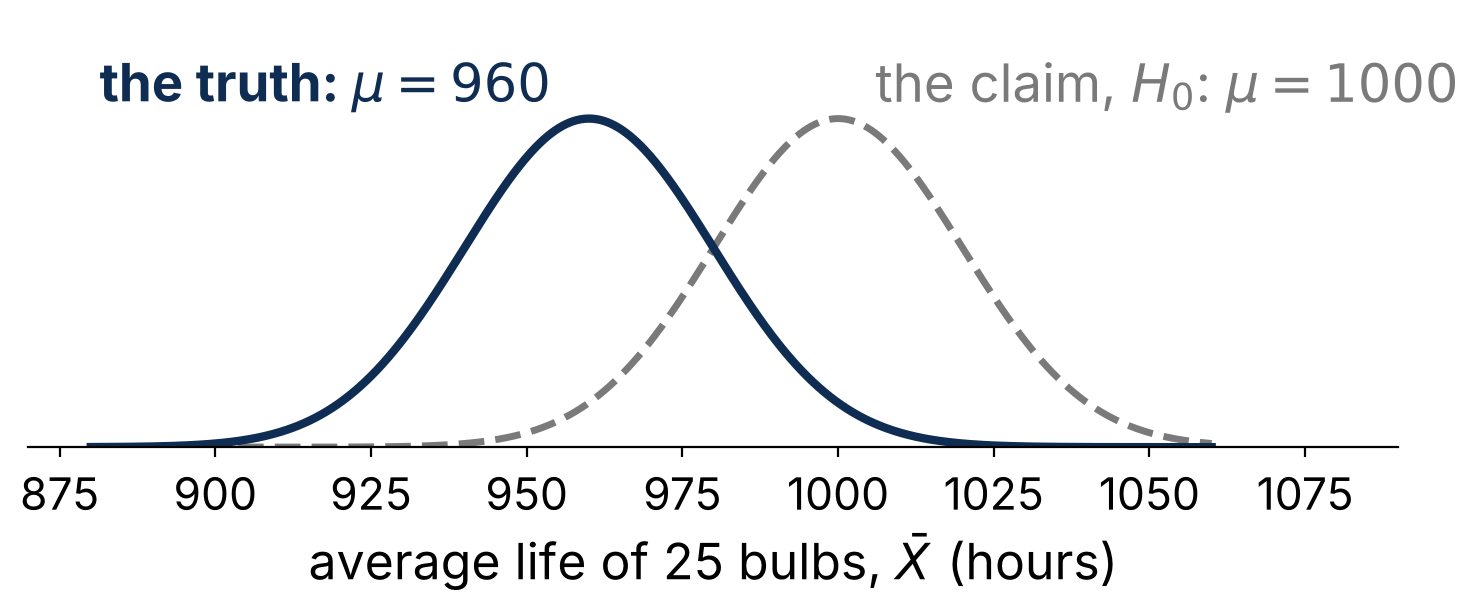

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

x = np.linspace(880, 1060, 600)
f0, f1 = stats.norm.pdf(x, MU0, SE), stats.norm.pdf(x, TRUTH, SE)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(x, f0, color=GRAY, lw=2.5, ls="--"); ax.plot(x, f1, color=NAVY, lw=3)
ax.text(MU0 + 6, f0.max() * 1.05, r"the claim, $H_0$: $\mu = 1000$", ha="left", fontsize=L, color=GRAY)
ax.text(TRUTH - 6, f1.max() * 1.05, r"the truth: $\mu = 960$", ha="right", fontsize=L, color=NAVY, fontweight="bold")
ax.set(xlabel=r"average life of 25 bulbs, $\bar X$ (hours)", ylim=(0, f0.max() * 1.3), xlim=(870, 1090)); clean(ax)
save(fig, "story.png")

## Part 1: the hypothesis test (we don't know the secret)

The consumer group's 25 bulbs average $\bar x = 968$ hours. Five steps:

1. $H_0: \mu = 1000$ vs. $H_1: \mu < 1000$ (one-sided: only "worse" is actionable).
2. $\alpha = 0.025$.
3. $z^* = \dfrac{968 - 1000}{100/\sqrt{25}} = -1.60$.
4. Critical value: reject if $z^* \le -z_{0.025} = -1.96$. $\;$ $p$-value $= P(Z \le -1.60) = 0.0548$.
5. $0.0548 > 0.025$: **fail to reject** $H_0$.

**Try it:** change `XBAR` (the sample mean) in the setup lines and re-run. What $\bar x$ would make us reject?

standard error = 20.0
z* = (968 - 1000) / 20 = -1.60
critical value: -z_0.025 = -1.96
p-value = P(Z <= -1.60) = 0.0548  ->  fail to reject H0


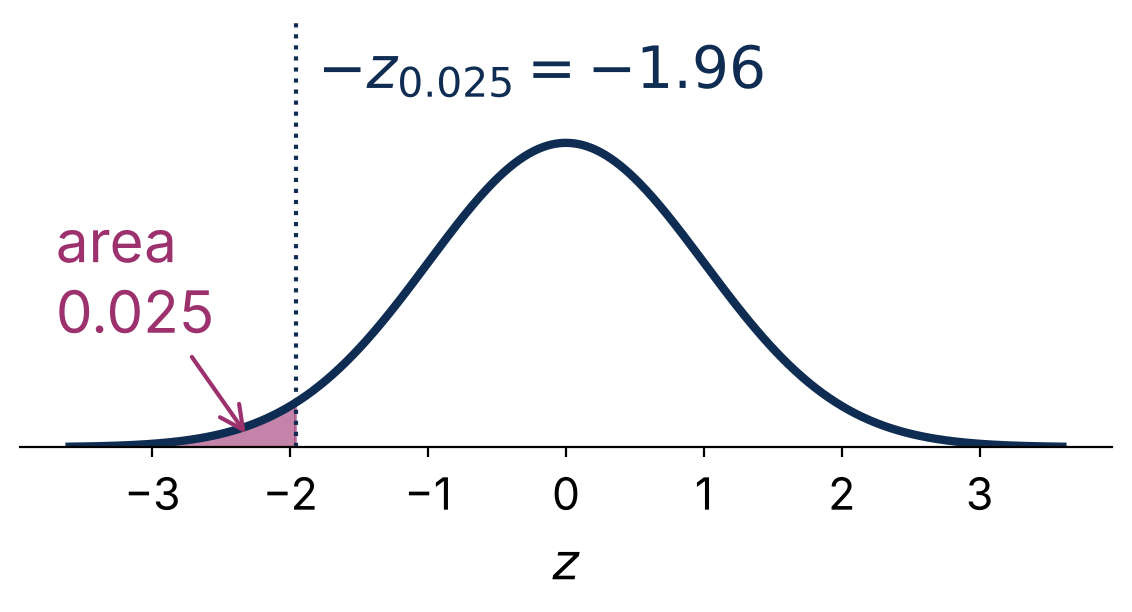

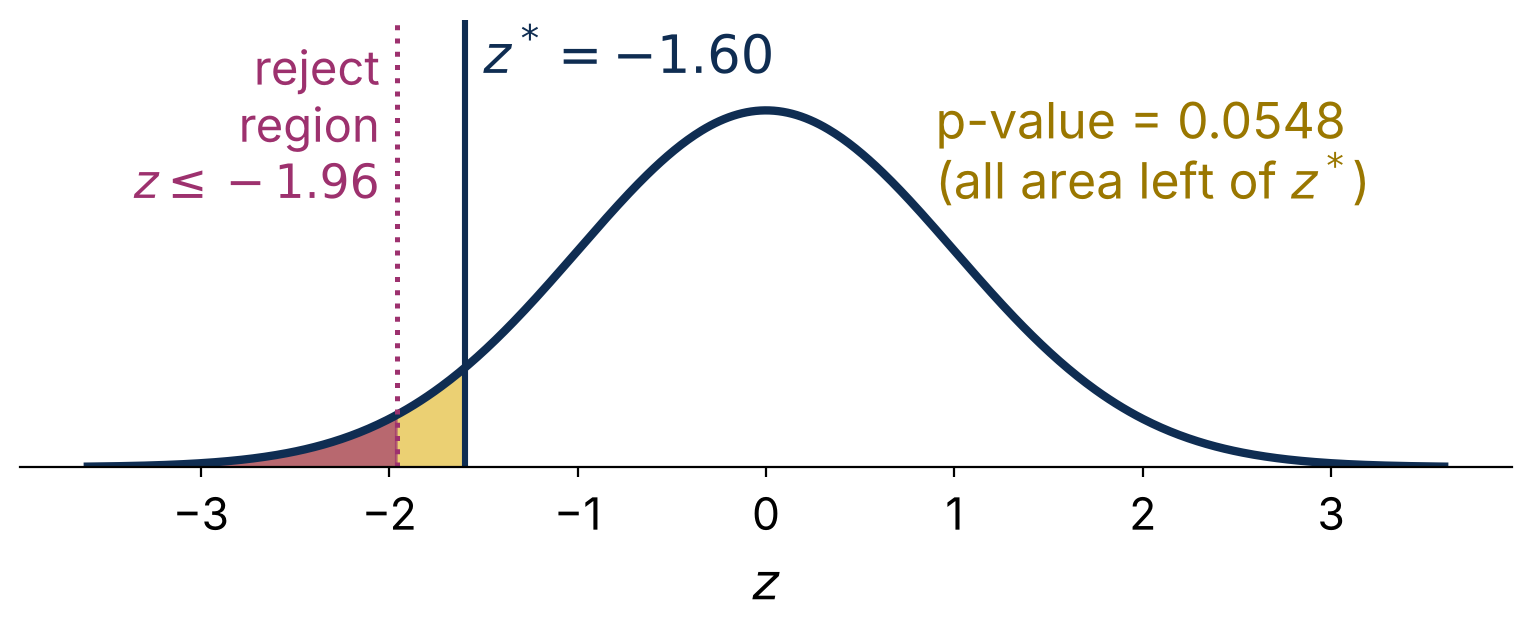

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

zstar = (XBAR - MU0) / SE
pval = stats.norm.cdf(zstar)
print(f"standard error = {SE:.1f}")
print(f"z* = ({XBAR} - {MU0}) / {SE:.0f} = {zstar:.2f}")
print(f"critical value: -z_0.025 = {-ZC:.2f}")
print(f"p-value = P(Z <= {zstar:.2f}) = {pval:.4f}  ->  {'reject' if pval <= ALPHA else 'fail to reject'} H0")

# Finding z_0.025: the left tail has area 0.025
z = np.linspace(-3.6, 3.6, 600); f = stats.norm.pdf(z)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(z, f, color=NAVY, lw=3)
ax.fill_between(z, f, where=z <= -ZC, color=MAGENTA, alpha=0.6)
ax.axvline(-ZC, color=NAVY, lw=1.5, ls=":")
ax.annotate("area\n0.025", xy=(-2.3, 0.012), xytext=(-3.7, 0.15), color=MAGENTA, fontsize=L + 2,
            arrowprops=dict(arrowstyle="->", color=MAGENTA, lw=1.5))
ax.text(-1.8, 0.47, r"$-z_{0.025} = -1.96$", fontsize=L + 2, color=NAVY, ha="left")
ax.set(xlabel="$z$", ylim=(0, 0.56)); ax.set_xticks([-3, -2, -1, 0, 1, 2, 3]); clean(ax)
save(fig, "bulbs_zcrit.png")

# Step 4: the reject region and the p-value
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(z, f, color=NAVY, lw=3)
ax.fill_between(z, f, where=z <= zstar, color=GOLD, alpha=0.55)
ax.fill_between(z, f, where=z <= -ZC, color=MAGENTA, alpha=0.65)
ax.axvline(-ZC, color=MAGENTA, lw=1.8, ls=":")
ax.axvline(zstar, color=NAVY, lw=2.2)
ax.text(zstar + 0.1, 0.44, rf"$z^* = {zstar:.2f}$", fontsize=L, color=NAVY, fontweight="bold")
ax.text(-ZC - 0.09, 0.30, "reject\nregion\n$z \\leq -1.96$", fontsize=L - 2, color=MAGENTA, ha="right")
ax.text(0.9, 0.30, f"p-value = {pval:.4f}\n" + r"(all area left of $z^*$)", fontsize=L - 1, color="#9a7700", ha="left")
ax.set(xlabel="$z$", ylim=(0, 0.5)); clean(ax)
save(fig, "bulbs_step4.png")

## The confidence interval — and the secret

$\bar x \pm z_{0.025}\,\dfrac{\sigma}{\sqrt n} = 968 \pm 1.96 \times 20 = (928.8,\ 1007.2)$. The claim $1000$ is inside, so we fail to reject.

Now the secret: the truth is $\mu = 960$. Our interval contains **both** $960$ and $1000$ — 25 bulbs couldn't tell them apart.
$H_0$ is false and we failed to reject it: a **Type II error**.

95% interval: 968 +/- 39.2 = (928.8, 1007.2)


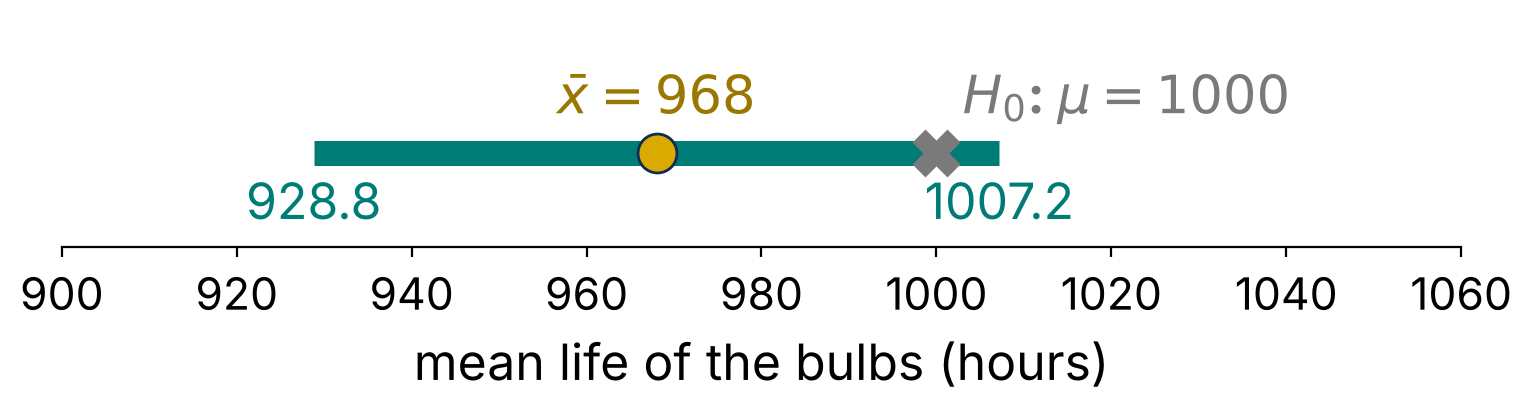

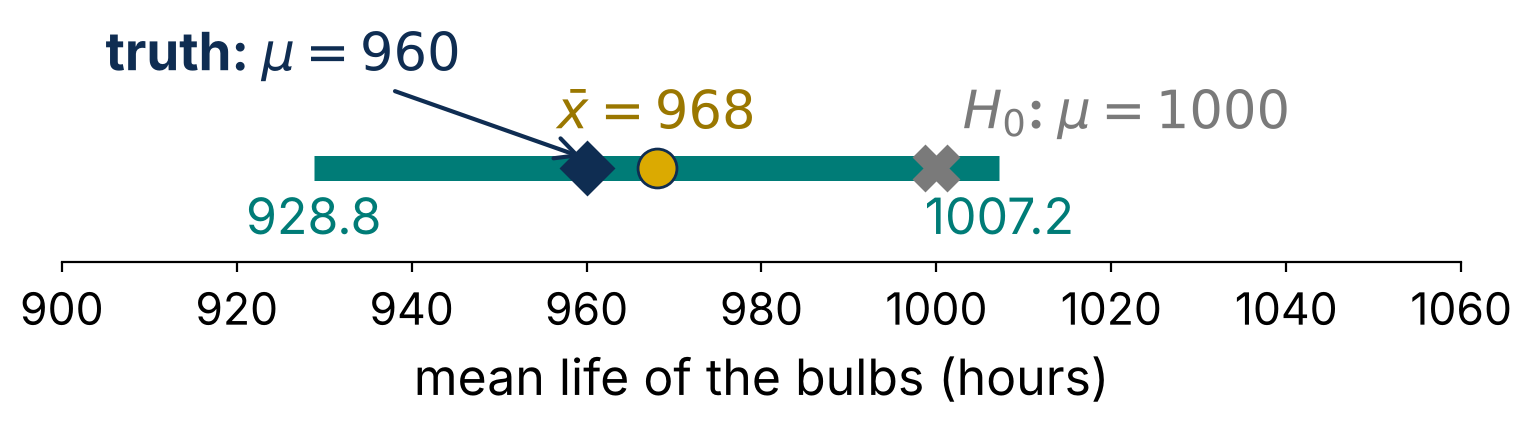

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

print(f"95% interval: {XBAR} +/- {ZC * SE:.1f} = ({LO:.1f}, {HI:.1f})")

def ci_axis(ax, show_truth=False):
    ax.plot([LO, HI], [0, 0], color=TEAL, lw=9, solid_capstyle="butt")
    ax.plot(XBAR, 0, "o", color=GOLD, ms=14, zorder=3, markeredgecolor=NAVY)
    ax.text(XBAR, 0.25, rf"$\bar x = {XBAR}$", ha="center", fontsize=L, color="#9a7700", fontweight="bold")
    ax.text(LO, -0.42, f"{LO:.1f}", ha="center", fontsize=L - 1, color=TEAL)
    ax.text(HI, -0.42, f"{HI:.1f}", ha="center", fontsize=L - 1, color=TEAL)
    ax.plot(MU0, 0, "X", color=GRAY, ms=16, zorder=4)
    ax.text(MU0 + 3, 0.25, H0LAB, ha="left", fontsize=L, color=GRAY, fontweight="bold")
    if show_truth:
        ax.plot(TRUTH, 0, "D", color=NAVY, ms=13, zorder=4)
        ax.annotate(TRLAB, xy=(TRUTH, 0.06), xytext=(905, 0.62), color=NAVY, fontsize=L,
                    fontweight="bold", arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.5))
    ax.set(ylim=(-0.6, 0.85), xlim=(900, 1060), xlabel="mean life of the bulbs (hours)"); clean(ax)

fig, ax = plt.subplots(figsize=(8, 2.4)); ci_axis(ax); save(fig, "bulbs_ci.png")
fig, ax = plt.subplots(figsize=(8, 2.4)); ci_axis(ax, show_truth=True); save(fig, "bulbs_ci_truth.png")

## Part 2: the cutoff in hours, and the confidence interval

Reject when $z^* \le -1.96$, i.e. when $\bar x \le 1000 - 1.96 \times 20 = 960.8$. If $H_0$ is true, that happens with probability $\alpha = 0.025$ (Type I error).

Equivalently: we reject exactly when the interval's upper end $\bar x + 39.2$ falls below $1000$.

cutoff = 1000 - 1.96 x 20 = 960.8
P(Type I) = P(Xbar <= 960.8 | mu = 1000) = 0.025


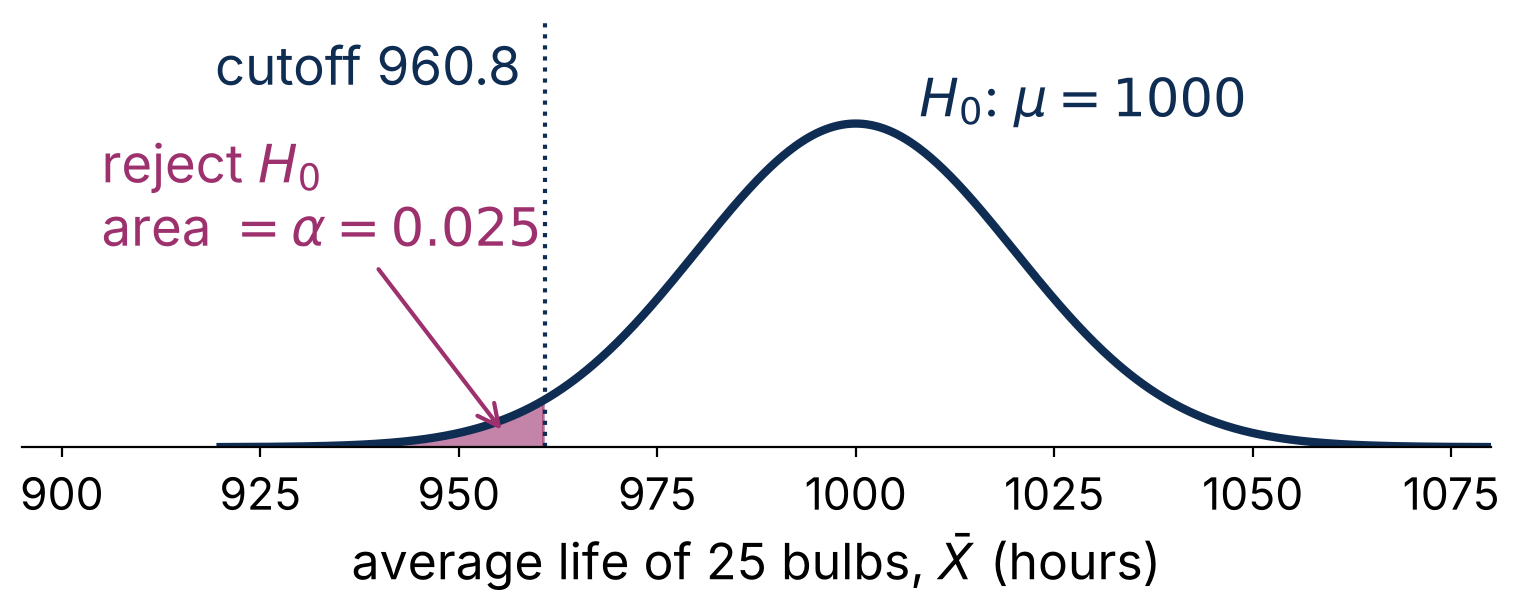

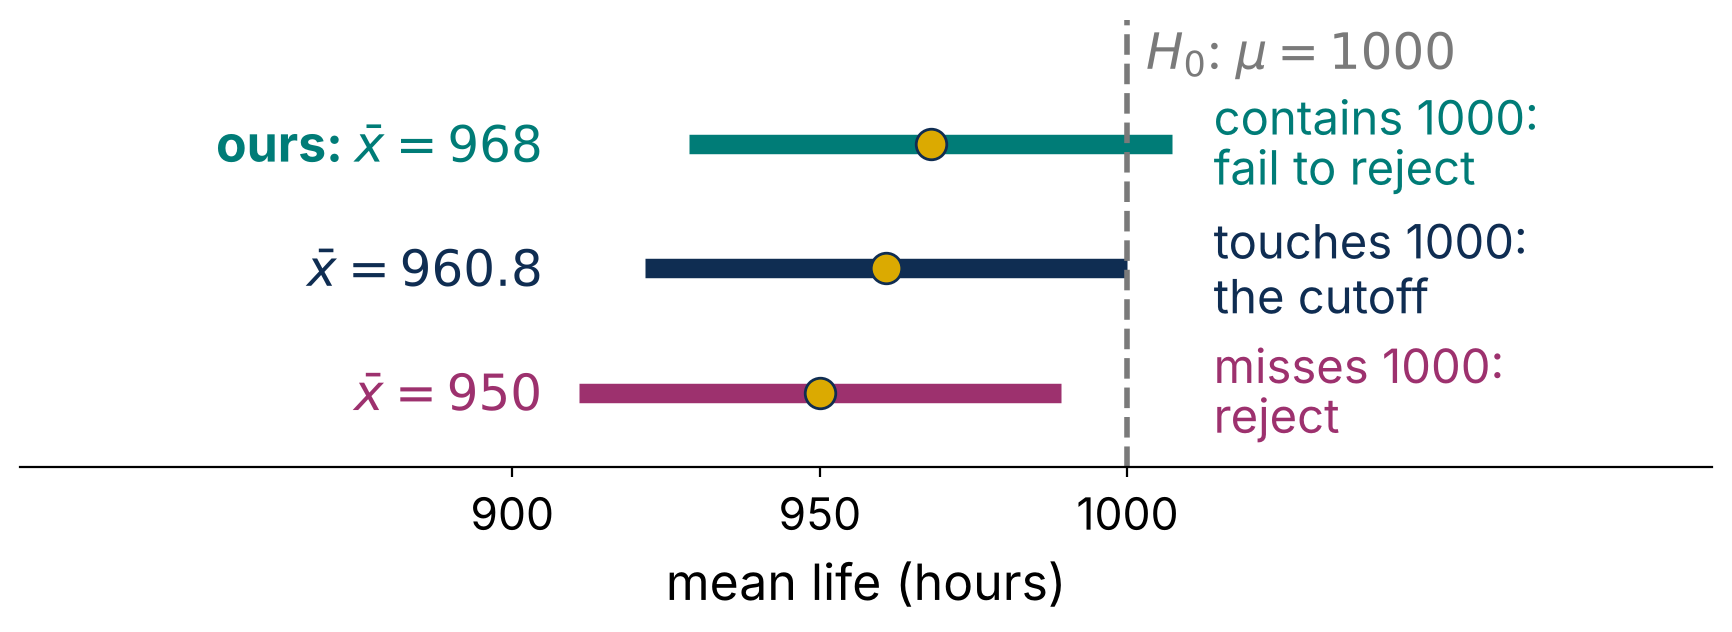

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

print(f"cutoff = {MU0} - {ZC:.2f} x {SE:.0f} = {CUT:.1f}")
print(f"P(Type I) = P(Xbar <= {CUT:.1f} | mu = 1000) = {stats.norm.cdf(CUT, MU0, SE):.3f}")

# Type I picture (the H0 world)
x = np.linspace(920, 1080, 600); f = stats.norm.pdf(x, MU0, SE)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(x, f, color=NAVY, lw=3)
ax.fill_between(x, f, where=x <= CUT, color=MAGENTA, alpha=0.6)
ax.axvline(CUT, color=NAVY, lw=1.5, ls=":")
ax.annotate("reject $H_0$\n" + r"area $= \alpha = 0.025$", xy=(CUT - 5, f.max() * 0.04), xytext=(905, f.max() * 0.62),
            color=MAGENTA, fontsize=L, arrowprops=dict(arrowstyle="->", color=MAGENTA, lw=1.5))
ax.text(CUT - 3, f.max() * 1.12, f"cutoff {CUT:.1f}", color=NAVY, fontsize=L, ha="right")
ax.text(MU0 + 8, f.max() * 1.02, H0LAB, ha="left", fontsize=L, color=NAVY)
ax.set(xlabel=r"average life of 25 bulbs, $\bar X$ (hours)", ylim=(0, f.max() * 1.32), xlim=(895, 1080)); clean(ax)
save(fig, "bulbs_typeI.png")

# Three possible intervals
fig, ax = plt.subplots(figsize=(9, 3.5))
cases = [(968, r"ours: $\bar x = 968$", TEAL, "contains 1000:\nfail to reject"),
         (CUT, rf"$\bar x = {CUT:.1f}$", NAVY, "touches 1000:\nthe cutoff"),
         (950, r"$\bar x = 950$", MAGENTA, "misses 1000:\nreject")]
for k, (xb, lab, col, verdict) in enumerate(cases):
    y = 2 - k
    ax.plot([xb - ZC * SE, xb + ZC * SE], [y, y], color=col, lw=7, solid_capstyle="butt")
    ax.plot(xb, y, "o", color=GOLD, ms=11, zorder=3, markeredgecolor=NAVY)
    ax.text(905, y, lab, va="center", ha="right", fontsize=L - 1, color=col, fontweight="bold")
    ax.text(1014, y, verdict, va="center", ha="left", fontsize=L - 2, color=col, linespacing=0.95)
ax.axvline(MU0, color=GRAY, lw=2, ls="--"); ax.text(MU0 + 3, 2.6, H0LAB, ha="left", fontsize=L - 1, color=GRAY)
ax.set(xlim=(820, 1095), ylim=(-0.6, 3.0), xlabel="mean life (hours)"); ax.set_xticks([900, 950, 1000]); clean(ax)
save(fig, "bulbs_ci_three.png")

## $\beta$ is a central limit theorem problem

**By the CLT**, if the truth is $\mu = 960$, then $\bar X \approx N(960,\ 20^2)$. So

$$\beta = P(\text{Type II error}) = P(\bar X > 960.8 \mid \mu = 960) = P\left(\frac{\bar X - 960}{20} > \frac{960.8 - 960}{20} \;\middle|\; \mu = 960\right) \approx P(Z > 0.04) = 0.4840.$$

The cutoff comes from $H_0$ ($1000$); the probability comes from the truth ($960$).
This is a special case: we can compute $\beta$ only because we were **told** the truth.

z = (960.8 - 960) / 20 = 0.04
beta = P(Z > 0.04) = 0.4840,   power = 0.5160


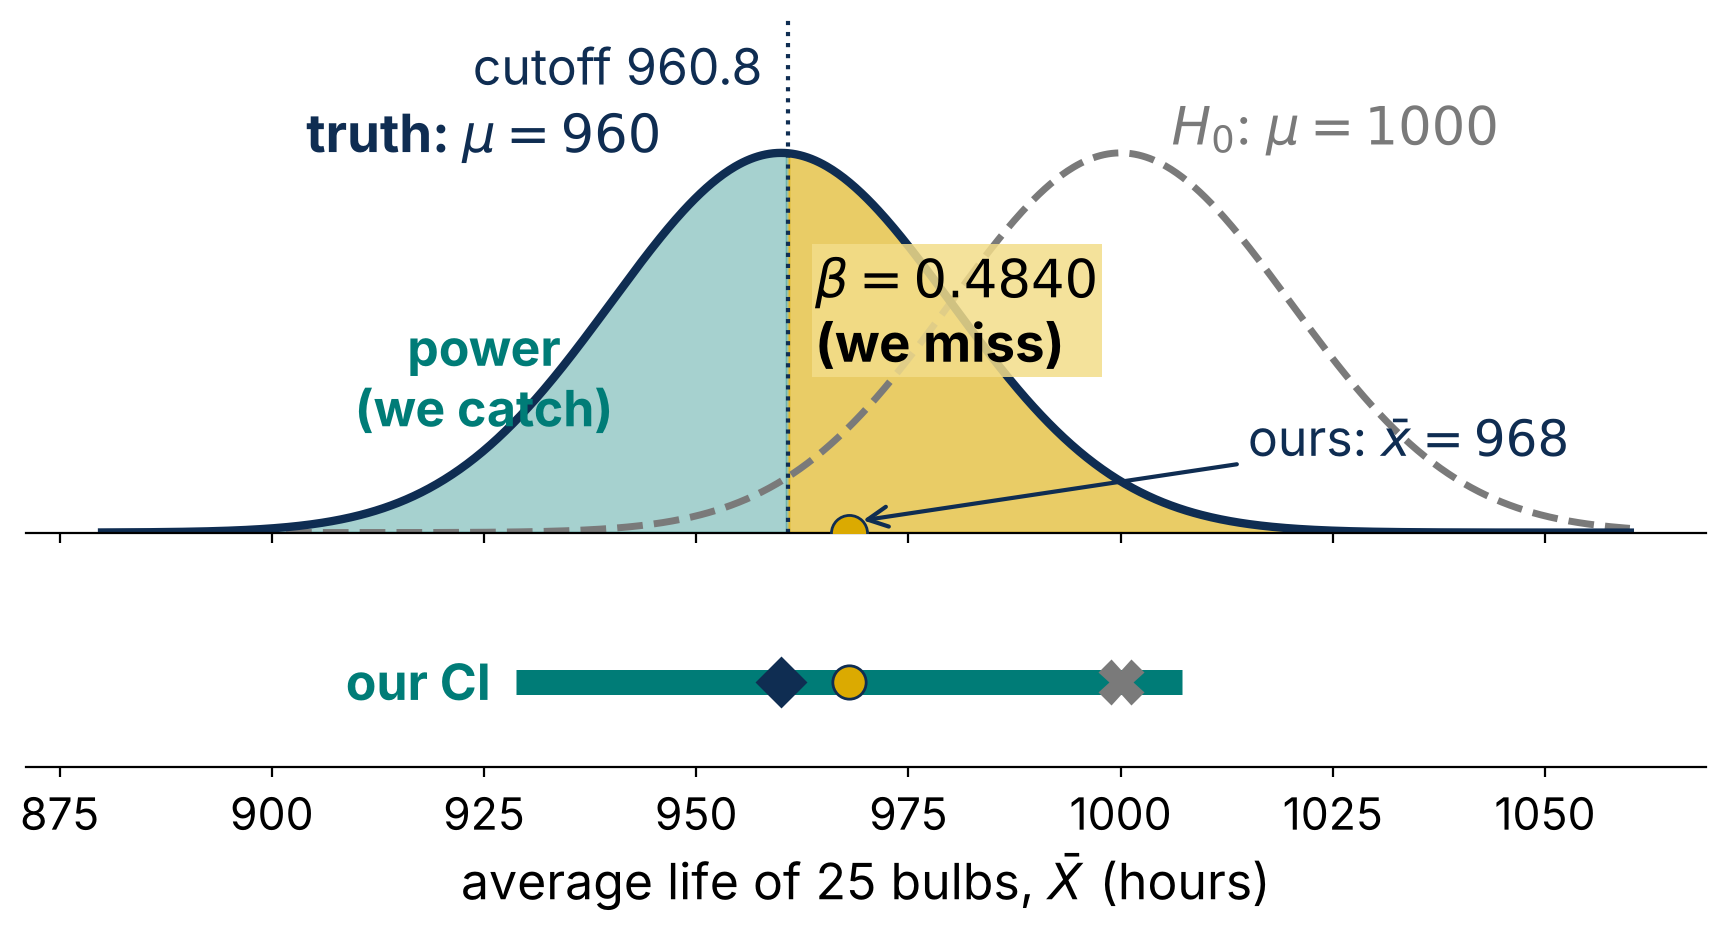

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

zb = (CUT - TRUTH) / SE
b = beta(TRUTH, N)
print(f"z = ({CUT:.1f} - {TRUTH}) / {SE:.0f} = {zb:.2f}")
print(f"beta = P(Z > {zb:.2f}) = {b:.4f},   power = {1 - b:.4f}")

x = np.linspace(880, 1060, 800)
f0, f1 = stats.norm.pdf(x, MU0, SE), stats.norm.pdf(x, TRUTH, SE)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.0), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(x, f0, color=GRAY, lw=2.5, ls="--"); ax.plot(x, f1, color=NAVY, lw=3)
ax.fill_between(x, f1, where=x > CUT, color=GOLD, alpha=0.6)
ax.fill_between(x, f1, where=x <= CUT, color=TEAL, alpha=0.35)
ax.axvline(CUT, color=NAVY, lw=1.5, ls=":")
ax.text(CUT - 3, f1.max() * 1.18, f"cutoff {CUT:.1f}", ha="right", fontsize=L - 1, color=NAVY)
ax.text(MU0 + 6, f0.max() * 1.02, H0LAB, ha="left", fontsize=L, color=GRAY)
ax.text(TRUTH - 14, f1.max() * 1.0, TRLAB, ha="right", fontsize=L, color=NAVY, fontweight="bold")
ax.text(964, f1.max() * 0.45, rf"$\beta = {b:.4f}$" + "\n(we miss)", fontsize=L, fontweight="bold",
        bbox=dict(facecolor="#f3dd8a", alpha=0.85, edgecolor="none", pad=1))
ax.text(925, f1.max() * 0.28, "power\n(we catch)", fontsize=L - 1, color=TEAL, ha="center", fontweight="bold")
ax.plot(XBAR, 0, "o", color=GOLD, ms=13, zorder=4, markeredgecolor=NAVY)
ax.annotate(rf"ours: $\bar x = {XBAR}$", xy=(XBAR + 1, 0.0006), xytext=(1015, f1.max() * 0.20), fontsize=L - 1, color=NAVY,
            arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.5))
ax.set(ylim=(0, f1.max() * 1.35)); clean(ax)
ax2.plot([LO, HI], [0, 0], color=TEAL, lw=9, solid_capstyle="butt")
ax2.plot(XBAR, 0, "o", color=GOLD, ms=12, zorder=3, markeredgecolor=NAVY)
ax2.plot(MU0, 0, "X", color=GRAY, ms=15, zorder=4); ax2.plot(TRUTH, 0, "D", color=NAVY, ms=12, zorder=4)
ax2.text(LO - 3, 0, "our CI", ha="right", va="center", fontsize=L - 1, color=TEAL, fontweight="bold")
ax2.set(ylim=(-1, 1), xlabel=r"average life of 25 bulbs, $\bar X$ (hours)"); clean(ax2)
save(fig, "bulbs_beta_ci.png")

## Simulation: many consumer groups

Each group tests 25 bulbs (truth $\mu = 960$) and builds its own interval $\bar x \pm 39.2$. A group misses the problem when its interval still contains $1000$.
The picture shows 20 groups; the second part runs 100,000 groups and compares with $\beta = 0.4840$.

**Try it:** change the seed, or change `TRUTH`.

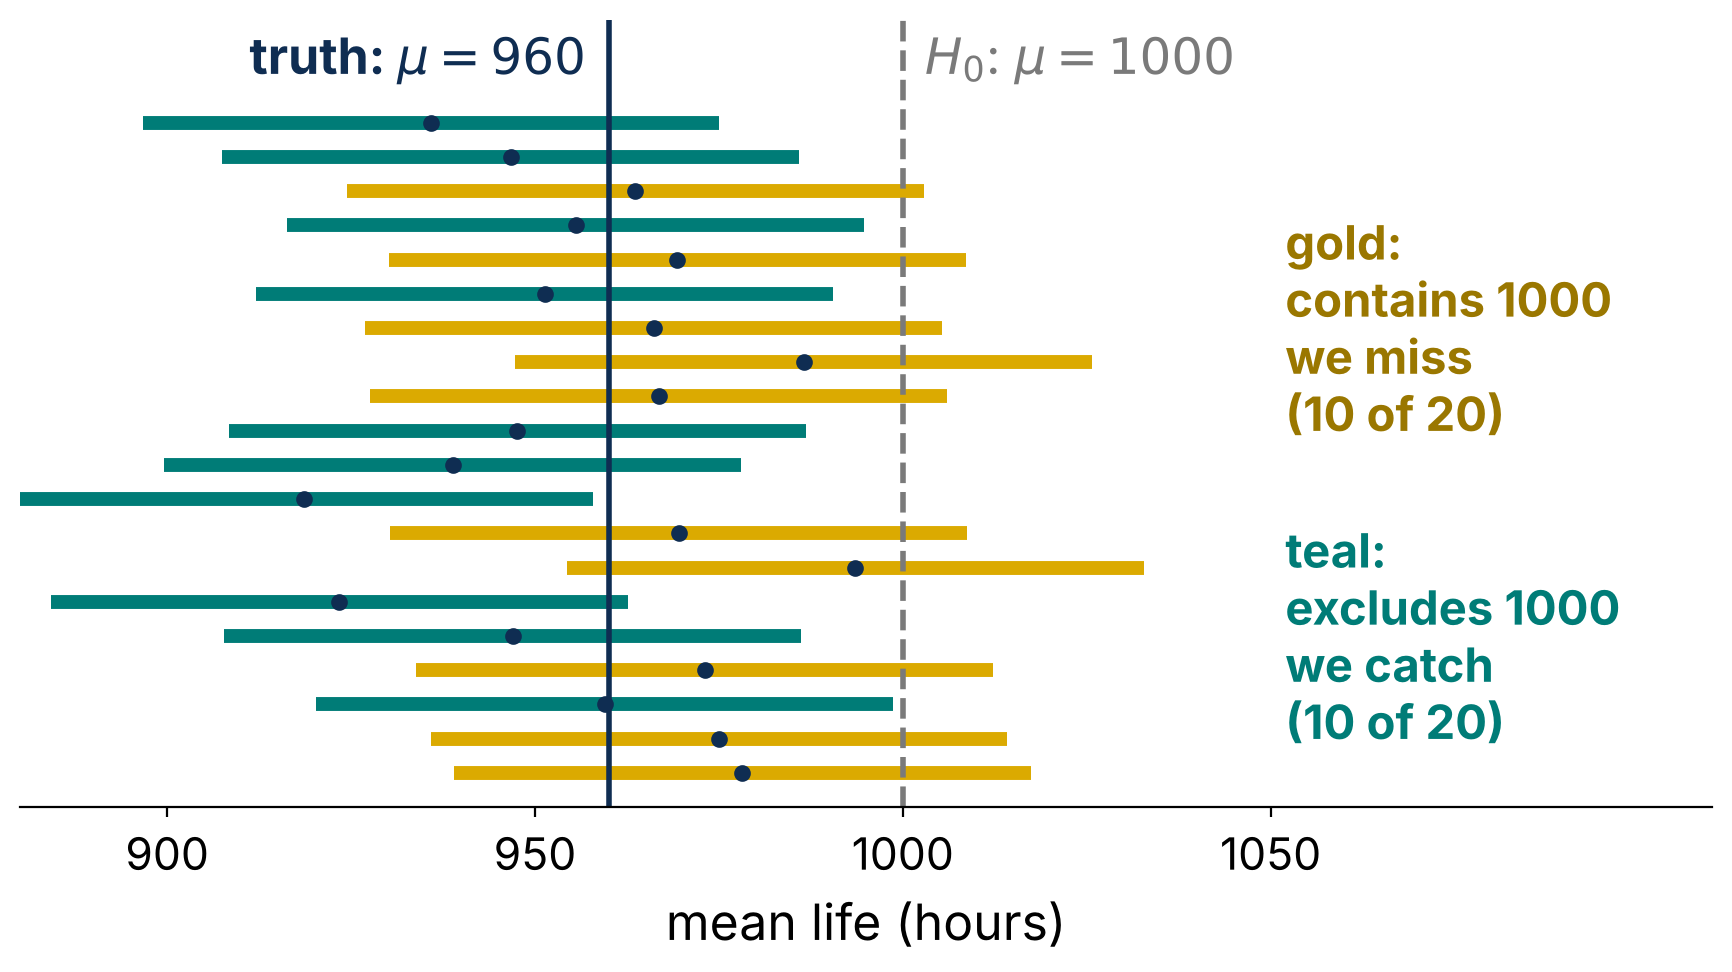

20 groups: 10 missed.   100,000 groups: fraction that failed to reject = 0.4823   (CLT: beta = 0.4840)


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

rng = np.random.default_rng(32)
xbars = rng.normal(TRUTH, SE, 20)
fig, ax = plt.subplots(figsize=(9, 5.2))
miss = 0
for k, xb in enumerate(xbars):
    lo, hi = xb - ZC * SE, xb + ZC * SE
    m = hi >= MU0; miss += m
    ax.plot([lo, hi], [k, k], color=GOLD if m else TEAL, lw=5, solid_capstyle="butt")
    ax.plot(xb, k, "o", color=NAVY, ms=5)
ax.axvline(MU0, color=GRAY, lw=2, ls="--"); ax.text(MU0 + 3, 20.4, H0LAB, fontsize=L - 1, color=GRAY)
ax.axvline(TRUTH, color=NAVY, lw=2); ax.text(TRUTH - 3, 20.4, TRLAB, fontsize=L - 1, color=NAVY, ha="right", fontweight="bold")
ax.text(1052, 13, f"gold:\ncontains 1000\nwe miss\n({miss} of 20)", fontsize=L - 2, color="#9a7700", fontweight="bold", va="center")
ax.text(1052, 4, f"teal:\nexcludes 1000\nwe catch\n({20 - miss} of 20)", fontsize=L - 2, color=TEAL, fontweight="bold", va="center")
ax.set(xlabel="mean life (hours)", ylim=(-1, 22), xlim=(880, 1110)); ax.set_xticks([900, 950, 1000, 1050]); clean(ax)
save(fig, "bulbs_20_cis.png")

# 100,000 groups: each draws 25 bulbs (here: normal lifetimes, sd 100) and runs the test
bulbs = rng.normal(TRUTH, SIGMA, size=(100_000, N))
fail = (bulbs.mean(axis=1) > CUT).mean()
print(f"20 groups: {miss} missed.   100,000 groups: fraction that failed to reject = {fail:.4f}   (CLT: beta = {beta(TRUTH, N):.4f})")

## Your Turn: the truth is $\mu = 940$

$\beta = P(\bar X > 960.8 \mid \mu = 940) \approx P\left(Z > \frac{960.8 - 940}{20}\right) = P(Z > 1.04) = 0.1492$, so the power is $0.8508$.
The farther the truth is from $H_0$, the easier it is to catch.

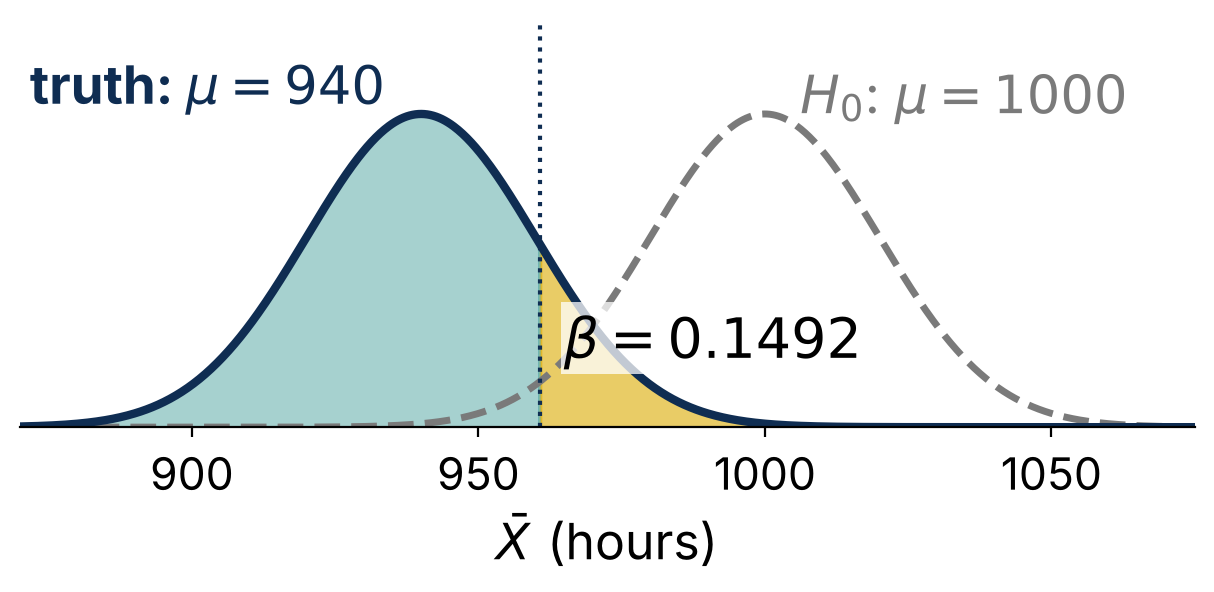

truth 940: beta = 0.1492, power = 0.8508


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

def beta_pic(n, mu_true, name, xlim, figsize=(6.6, 3.3)):
    s = se(n); c = cutoff(n); b = beta(mu_true, n)
    x = np.linspace(*xlim, 800)
    f0, f1 = stats.norm.pdf(x, MU0, s), stats.norm.pdf(x, mu_true, s)
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, f0, color=GRAY, lw=2.5, ls="--"); ax.plot(x, f1, color=NAVY, lw=3)
    ax.fill_between(x, f1, where=x > c, color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=x <= c, color=TEAL, alpha=0.35)
    ax.axvline(c, color=NAVY, lw=1.5, ls=":")
    ax.text(MU0 + (xlim[1] - xlim[0]) * 0.03, f0.max(), H0LAB, ha="left", fontsize=L, color=GRAY)
    ax.text(mu_true - (xlim[1] - xlim[0]) * 0.03, f1.max() * 1.03, rf"truth: $\mu = {mu_true}$", ha="right",
            fontsize=L, color=NAVY, fontweight="bold")
    ax.text(c + (xlim[1] - xlim[0]) * 0.02, f1.max() * 0.22, rf"$\beta = {b:.4f}$", fontsize=L + 1, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1))
    ax.set(xlabel=r"$\bar X$ (hours)", xlim=xlim, ylim=(0, max(f0.max(), f1.max()) * 1.3)); clean(ax)
    save(fig, name)
    return b

b = beta_pic(25, 940, "bulbs_beta_940.png", (870, 1075))
print(f"truth 940: beta = {b:.4f}, power = {1 - b:.4f}")

## More data: $n = 100$ (the CLT again)

The CLT says the standard error is $\sigma/\sqrt n$: $100/\sqrt{25} = 20$ but $100/\sqrt{100} = 10$. Four times the data, half the spread.

* The cutoff moves to $1000 - 1.96 \times 10 = 980.4$, but $\alpha$ stays $0.025$.
* $\beta = P(\bar X > 980.4 \mid \mu = 960) \approx P(Z > 2.04) = 0.0207$ (it was $0.4840$).

n =  25: standard error =   20, cutoff = 960.8, alpha = 0.025, beta(960) = 0.4840
n = 100: standard error =   10, cutoff = 980.4, alpha = 0.025, beta(960) = 0.0207


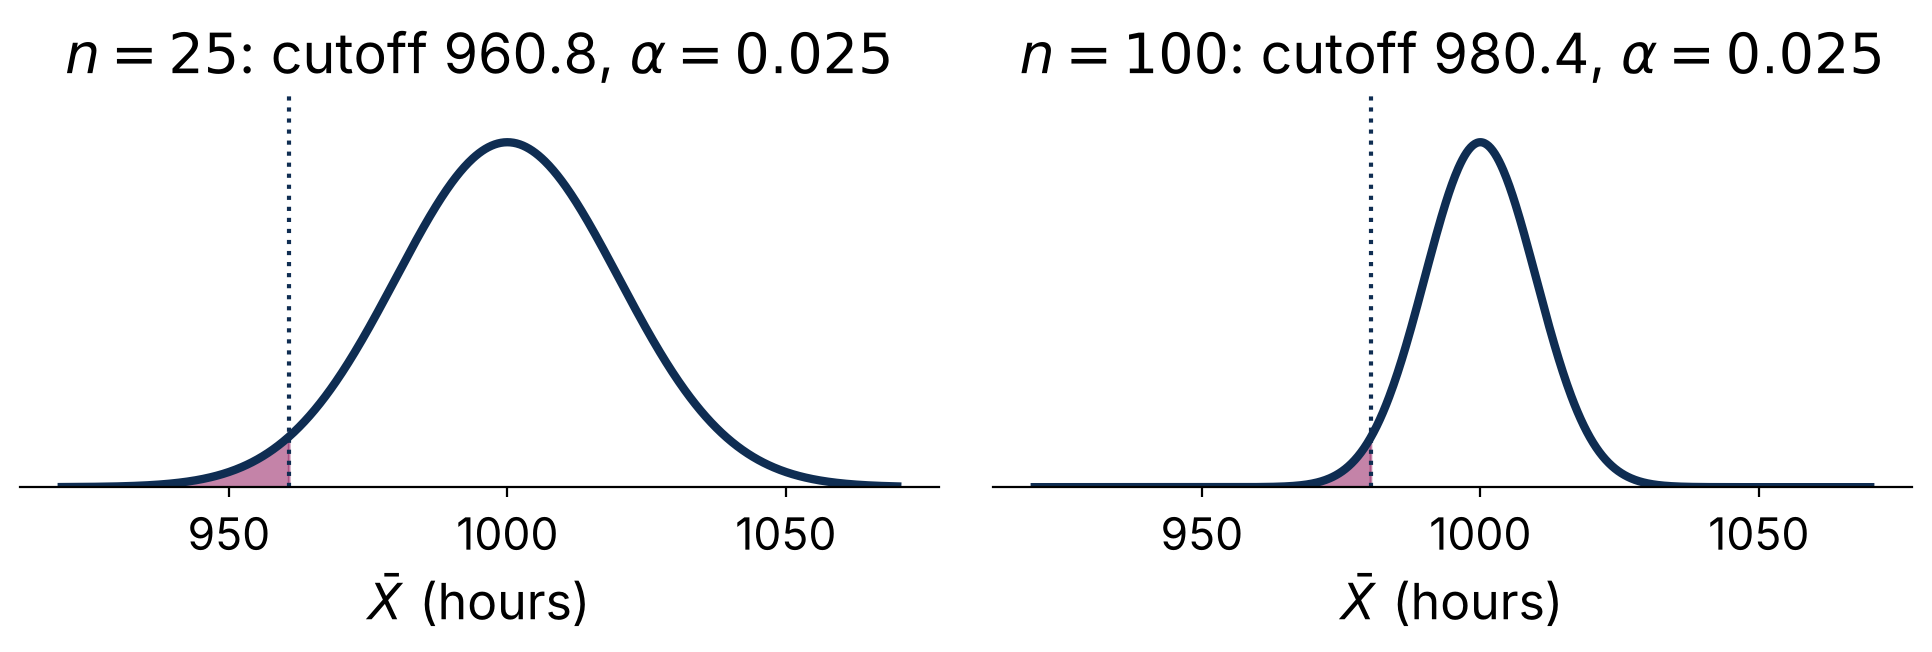

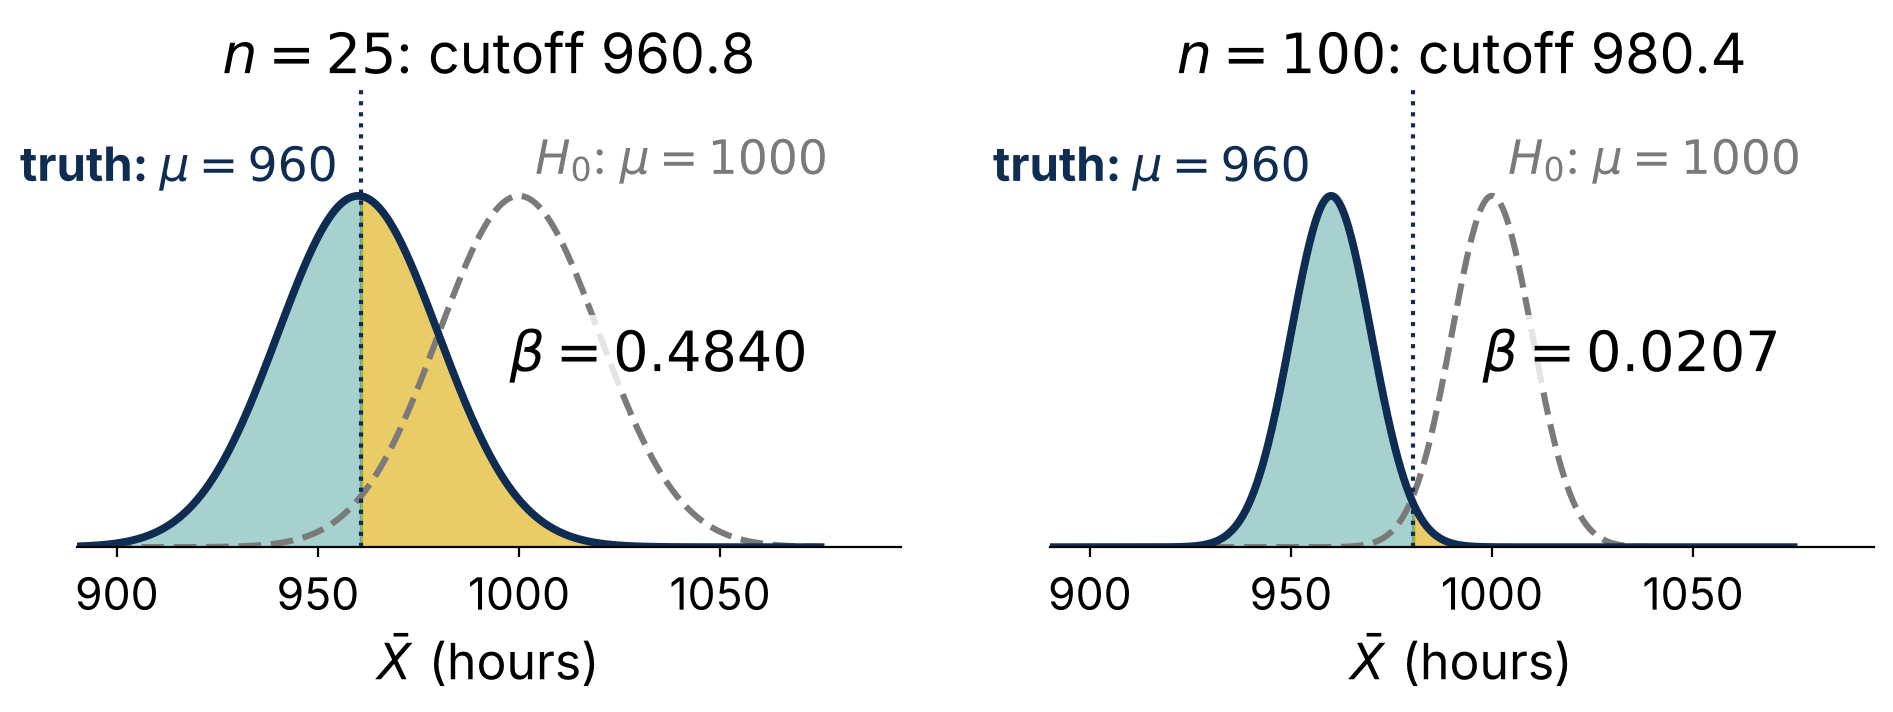

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

for n in (25, 100):
    print(f"n = {n:3d}: standard error = {se(n):4.0f}, cutoff = {cutoff(n):.1f}, "
          f"alpha = {stats.norm.cdf(cutoff(n), MU0, se(n)):.3f}, beta(960) = {beta(960, n):.4f}")

# alpha for n = 25 and n = 100
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
x = np.linspace(920, 1070, 800)
for ax, n in zip(axes, [25, 100]):
    s = se(n); c = cutoff(n); f = stats.norm.pdf(x, MU0, s)
    ax.plot(x, f, color=NAVY, lw=3)
    ax.fill_between(x, f, where=x <= c, color=MAGENTA, alpha=0.6)
    ax.axvline(c, color=NAVY, lw=1.5, ls=":")
    ax.set_title(rf"$n = {n}$: cutoff {c:.1f}, $\alpha = 0.025$", fontsize=L + 1)
    ax.set(xlabel=r"$\bar X$ (hours)", ylim=(0, f.max() * 1.15)); clean(ax)
save(fig, "alpha_n25_n100.png")

# beta for n = 25 and n = 100
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharex=True)
x = np.linspace(890, 1075, 800)
for ax, n in zip(axes, [25, 100]):
    s = se(n); c = cutoff(n); b = beta(960, n)
    f0, f1 = stats.norm.pdf(x, MU0, s), stats.norm.pdf(x, 960, s)
    ax.plot(x, f0, color=GRAY, lw=2.2, ls="--"); ax.plot(x, f1, color=NAVY, lw=2.8)
    ax.fill_between(x, f1, where=x > c, color=GOLD, alpha=0.6)
    ax.fill_between(x, f1, where=x <= c, color=TEAL, alpha=0.35)
    ax.axvline(c, color=NAVY, lw=1.5, ls=":")
    ax.set_title(rf"$n = {n}$: cutoff {c:.1f}", fontsize=L + 1)
    ax.text(955, f1.max() * 1.04, r"truth: $\mu = 960$", ha="right", fontsize=L - 2, color=NAVY, fontweight="bold")
    ax.text(1004, f0.max() * 1.06, r"$H_0$: $\mu = 1000$", ha="left", fontsize=L - 2, color=GRAY)
    ax.text(1072, f1.max() * 0.5, rf"$\beta = {b:.4f}$", ha="right", fontsize=L + 1, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
    ax.set(xlabel=r"$\bar X$ (hours)", ylim=(0, f1.max() * 1.3), xlim=(890, 1095)); ax.set_xticks([900, 950, 1000, 1050]); clean(ax)
save(fig, "beta_n25_n100.png")

## Extra: the power curve

$\beta$ depends on the truth. Here is the power $1 - \beta$ for every possible true mean, for $n = 25$ and $n = 100$.

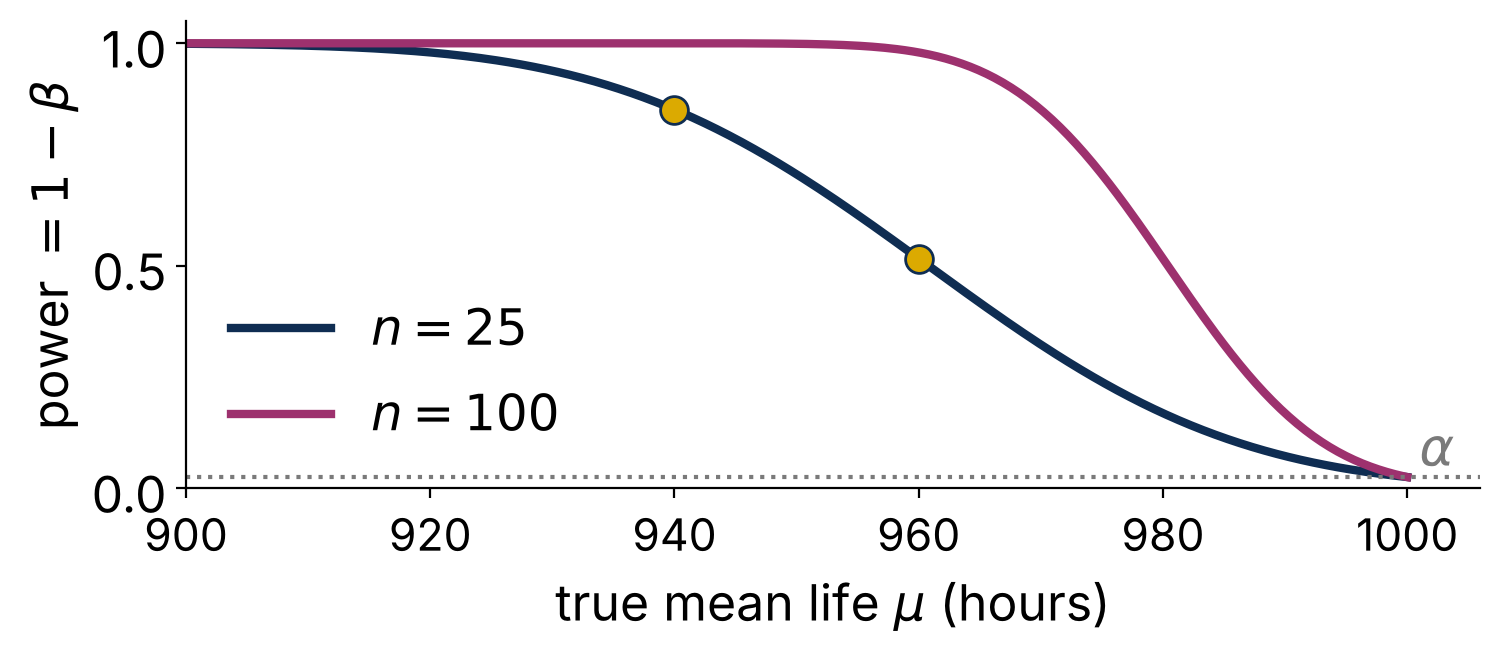

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

mus = np.linspace(900, 1000, 300)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(mus, 1 - beta(mus, 25), color=NAVY, lw=3, label=r"$n = 25$")
ax.plot(mus, 1 - beta(mus, 100), color=MAGENTA, lw=3, label=r"$n = 100$")
for mu in (960, 940):
    ax.plot(mu, 1 - beta(mu, 25), "o", color=GOLD, ms=10, zorder=3, markeredgecolor=NAVY)
ax.axhline(ALPHA, color=GRAY, ls=":", lw=1.5); ax.text(1001, 0.05, r"$\alpha$", color=GRAY, fontsize=L)
ax.set(xlabel=r"true mean life $\mu$ (hours)", ylabel=r"power $= 1 - \beta$", ylim=(0, 1.05), xlim=(900, 1006))
ax.legend(frameon=False, loc="lower left")
save(fig, "power_curve.png")

## In the real world: a power analysis

In real life nobody tells us the truth. So researchers ask $\beta$ as a "what if" question **before** collecting data:
pick the smallest difference that matters, pick $\alpha$ and the power they want, and solve for $n$.

* For 90% power if $\mu = 960$: the cutoff must sit $z_{0.10} \approx 1.28$ standard errors above $960$, so
  $1000 - 1.96\,\frac{100}{\sqrt n} = 960 + 1.28\,\frac{100}{\sqrt n}$, giving $\sqrt n \approx 8.1$ and $n \approx 66$.
* Flip it: with $n = 25$, 80% power only for a drop of $(1.96 + 0.84) \times 20 = 56$ hours.

**Try it:** change `diff` (the smallest difference that matters) or `power`.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 18, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelsize": 18, "xtick.labelsize": 16, "mathtext.fontset": "dejavusans"})
L = 19   # label size (big, so the back row can read the slides)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTDIR / name, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
def clean(ax):
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

# The light bulb example: H0: mu = 1000 vs H1: mu < 1000, sigma = 100 known, alpha = 0.025
MU0, SIGMA, ALPHA, N = 1000, 100, 0.025, 25
ZC = stats.norm.ppf(1 - ALPHA)                       # z_0.025 = 1.96
def se(n): return SIGMA / np.sqrt(n)                  # standard error, from the CLT
def cutoff(n): return MU0 - ZC * se(n)                # reject H0 when xbar <= cutoff
def beta(mu, n): return stats.norm.sf((cutoff(n) - mu) / se(n))   # P(Xbar > cutoff | true mean mu)
TRUTH, XBAR = 960, 968                                # the hidden truth, and the consumer group's sample mean
SE = se(N); CUT = cutoff(N)
LO, HI = XBAR - ZC * SE, XBAR + ZC * SE               # our confidence interval
H0LAB, TRLAB = r"$H_0$: $\mu = 1000$", r"truth: $\mu = 960$"

diff, power = 40, 0.90                     # smallest difference that matters, and the power we want
z_beta = stats.norm.ppf(power)             # 1.28 for 90% power
n_needed = ((ZC + z_beta) * SIGMA / diff) ** 2
n_round = int(np.ceil(n_needed))
print(f"n needed = ((1.96 + {z_beta:.2f}) x {SIGMA} / {diff})^2 = {n_needed:.1f}  ->  {n_round} bulbs")
print(f"check: with n = {n_round}, power at mu = {MU0 - diff} is {1 - beta(MU0 - diff, n_round):.3f}")

mde = (ZC + stats.norm.ppf(0.80)) * se(25)
print(f"with n = 25, 80% power only for a drop of {mde:.0f} hours (true mean {MU0 - mde:.0f} or less)")

n needed = ((1.96 + 1.28) x 100 / 40)^2 = 65.7  ->  66 bulbs
check: with n = 66, power at mu = 960 is 0.901
with n = 25, 80% power only for a drop of 56 hours (true mean 944 or less)
